##  Linguagem de Programação Aplicada
---

# Importação das bibliotecas

In [93]:
# Biblioteca Pandas - Manipulação de dados
import pandas as pd
# Biblioteca Seaborn - Criação de gráficos
import seaborn as sns
# Biblioteca Matplotlib - Criação de gráficos
import matplotlib.pyplot as plt

# OPCIONAL - Biblioteca para ignorar mensagens de warning (aviso) ao rodar uma célula de código
import warnings
warnings.filterwarnings('ignore')

In [94]:
# Bibliotecas de machine learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import LabelEncoder

# Métricas de avaliação dos modelos
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# a) Carregamento dos dados

In [95]:
# Função read_csv para importar os dados da pasta do computador
dados = pd.read_csv('precos_carros_brasil.csv')

In [96]:
# Listando o nome das colunas
dados.columns

Index(['year_of_reference', 'month_of_reference', 'fipe_code',
       'authentication', 'brand', 'model', 'fuel', 'gear', 'engine_size',
       'year_model', 'avg_price_brl'],
      dtype='str')

In [97]:
# Imprimindo as 5 primeiras linhas
dados.head()

,year_of_reference,month_of_reference,fipe_code,authentication,brand,model,fuel,gear,engine_size,year_model,avg_price_brl
0,2021.0,January,004001-0,cfzlctzfwrcp,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Gasoline,manual,1,2002.0,9162.0
1,2021.0,January,004001-0,cdqwxwpw3y2p,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Gasoline,manual,1,2001.0,8832.0
2,2021.0,January,004001-0,cb1t3xwwj1xp,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Gasoline,manual,1,2000.0,8388.0
3,2021.0,January,004001-0,cb9gct6j65r0,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Alcohol,manual,1,2000.0,8453.0
4,2021.0,January,004003-7,g15wg0gbz1fx,GM - Chevrolet,Corsa Pick-Up GL/ Champ 1.6 MPFI / EFI,Gasoline,manual,"1,6",2001.0,12525.0


In [98]:
# Observando número de linhas e colunas
dados.shape

(267542, 11)

In [99]:
# Imprime o tipo de dado em cada coluna: object - variáveis categóricas; float64 e int64 - variáveis numéricas
dados.dtypes

year_of_reference     float64
month_of_reference        str
fipe_code                 str
authentication            str
brand                     str
model                     str
fuel                      str
gear                      str
engine_size               str
year_model            float64
avg_price_brl         float64
dtype: object

In [100]:
# Verificando se existem valores faltantes nos dados 
dados.isna().any()

year_of_reference     True
month_of_reference    True
fipe_code             True
authentication        True
brand                 True
model                 True
fuel                  True
gear                  True
engine_size           True
year_model            True
avg_price_brl         True
dtype: bool

In [101]:
# Verificando a quantidade de valores faltantes por coluna
dados.isna().sum()

year_of_reference     65245
month_of_reference    65245
fipe_code             65245
authentication        65245
brand                 65245
model                 65245
fuel                  65245
gear                  65245
engine_size           65245
year_model            65245
avg_price_brl         65245
dtype: int64

# Tratamento de dados

In [102]:
# dropar linhas completamente vazias
dados = dados.dropna(how='all')

In [103]:
# validar novamente se existem valores faltantes nos dados 
dados.isna().any()

year_of_reference     False
month_of_reference    False
fipe_code             False
authentication        False
brand                 False
model                 False
fuel                  False
gear                  False
engine_size           False
year_model            False
avg_price_brl         False
dtype: bool

In [104]:
# Verificando novamente a quantidade de valores faltantes por coluna
dados.isna().sum()

year_of_reference     0
month_of_reference    0
fipe_code             0
authentication        0
brand                 0
model                 0
fuel                  0
gear                  0
engine_size           0
year_model            0
avg_price_brl         0
dtype: int64

In [105]:
# validar linhas duplicadas
dados.duplicated().sum()

np.int64(2)

In [106]:
# remover linhas duplicadas
dados.drop_duplicates(inplace=True)

# Organização dos dados para modelagem de machine learning

### Divisão dos dados

Para a divisão de dados, optou-se por:

* Conjunto de Treinamento (X_train, y_train): Conjunto utilizado para treinar o modelo. Neste caso, 75% dos dados são selecionados para treinamento, conforme definido pela variável train_ratio.

* Conjunto de Teste (X_test, y_test): Conjunto utilizado para avaliar o desempenho do modelo em dados não vistos durante o treinamento. Neste caso, 25% dos dados são reservados para teste

Algoritmos de machine learning de Regressão não aceitam variáveis categóricas e, por isso, precisamos utilizar técnicas para converter as classes em números

In [107]:
# Variável dados_num contém apenas variáveis numéricas de interesse (exclui o as variáveis indesejáveis)
dados_num = dados.drop([
    'month_of_reference',
    'fipe_code',
    'authentication'
], axis=1)
dados_num.head()

,year_of_reference,brand,model,fuel,gear,engine_size,year_model,avg_price_brl
0,2021.0,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Gasoline,manual,1,2002.0,9162.0
1,2021.0,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Gasoline,manual,1,2001.0,8832.0
2,2021.0,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Gasoline,manual,1,2000.0,8388.0
3,2021.0,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Alcohol,manual,1,2000.0,8453.0
4,2021.0,GM - Chevrolet,Corsa Pick-Up GL/ Champ 1.6 MPFI / EFI,Gasoline,manual,"1,6",2001.0,12525.0


In [108]:
# Identificar colunas categóricas
categoricas_cols = ['brand', 'model', 'fuel', 'gear', 'engine_size']

# Aplicando LabelEncoder (mesmo padrão da professora)
le = LabelEncoder()

for col in categoricas_cols:
    dados_num[col] = le.fit_transform(dados_num[col])

dados_num.head()

,year_of_reference,brand,model,fuel,gear,engine_size,year_model,avg_price_brl
0,2021.0,2,297,2,1,0,2002.0,9162.0
1,2021.0,2,297,2,1,0,2001.0,8832.0
2,2021.0,2,297,2,1,0,2000.0,8388.0
3,2021.0,2,297,0,1,0,2000.0,8453.0
4,2021.0,2,260,2,1,5,2001.0,12525.0


In [109]:
# Imprime o tipo de dado em cada coluna: object - variáveis categóricas; float64 e int64 - variáveis numéricas
dados_num.dtypes

year_of_reference    float64
brand                  int64
model                  int64
fuel                   int64
gear                   int64
engine_size            int64
year_model           float64
avg_price_brl        float64
dtype: object

In [110]:
# Renomear a coluna avg_price_brl para avg_price
dados_num = dados_num.rename(columns={'avg_price_brl': 'avg_price'})
# Definindo variável target
target = 'avg_price'


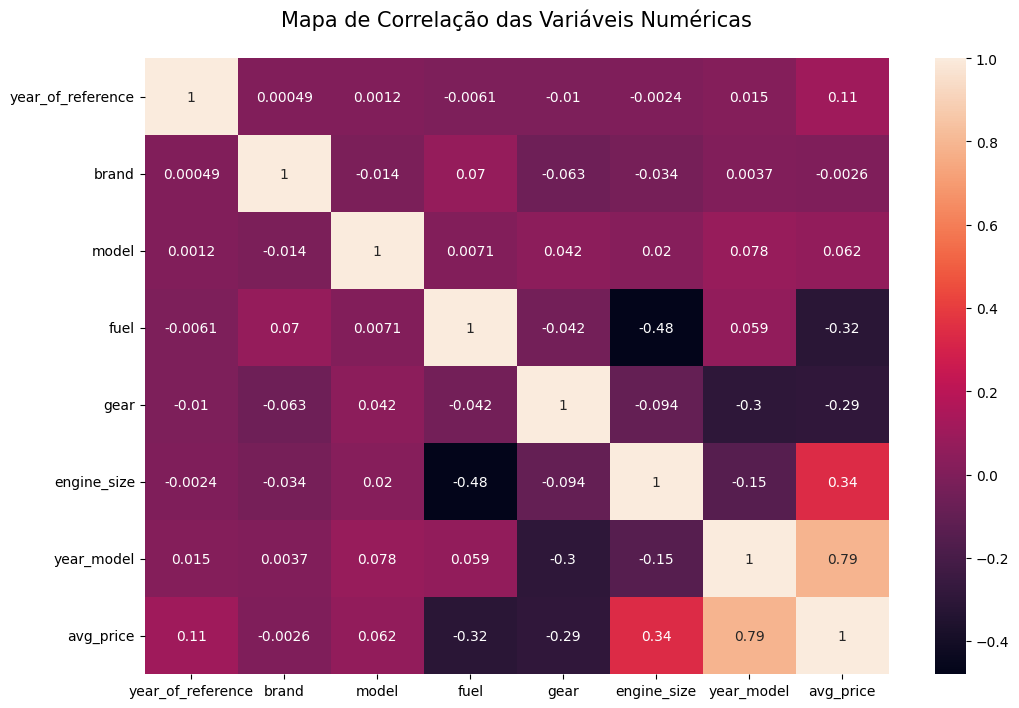

In [111]:
plt.figure(figsize=(12,8))
sns.heatmap(dados_num.corr("spearman"), annot = True)
plt.title("Mapa de Correlação das Variáveis Numéricas\n", fontsize = 15)
plt.show()

# b) Divisão Treino / Teste (75 / 25)

In [112]:
# Variável X contém apenas variáveis numéricas de interesse para a análise, excluindo a variável target
X = dados_num.drop([target], axis=1)
X.head()

,year_of_reference,brand,model,fuel,gear,engine_size,year_model
0,2021.0,2,297,2,1,0,2002.0
1,2021.0,2,297,2,1,0,2001.0
2,2021.0,2,297,2,1,0,2000.0
3,2021.0,2,297,0,1,0,2000.0
4,2021.0,2,260,2,1,5,2001.0


In [113]:
# Variável Y contém apenas a variável target - avg_price
Y = dados_num[target]
Y.head()

0     9162.0
1     8832.0
2     8388.0
3     8453.0
4    12525.0
Name: avg_price, dtype: float64

In [114]:
# Divisão: 25% dos dados são de teste e 75% de treinamento
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42)

In [115]:
# Observando os dados de treinamento
print(X_train.shape)
X_train.head(1)

(151721, 7)


,year_of_reference,brand,model,fuel,gear,engine_size,year_model
156364,2022.0,0,364,1,1,10,2020.0


In [116]:
# Observando os dados de teste
print(X_test.shape)
X_test.head(1)

(50574, 7)


,year_of_reference,brand,model,fuel,gear,engine_size,year_model
180633,2022.0,0,1235,2,1,5,2015.0


In [117]:
# Observando a variável target
Y_test.head()

180633    42595.0
13130     10989.0
163315     9087.0
121464    26965.0
14044     57102.0
Name: avg_price, dtype: float64

# c) Treinamento do modelo

- Random Forest - combina a saída de múltiplas árvores de decisão para chegar a um único resultado
- XGBoost - significa “eXtreme Gradient Boosting”. Essa técnica é baseada no conceito de boosting, que consiste em combinar vários modelos fracos para criar um modelo forte

#### c.1 Random Forest - Opção Sem Parâmetros

In [118]:
# Algoritmo Random Forest, sem especificar nenhum parâmetro (número de árvores, número de ramificações, etc)
model_rf = RandomForestRegressor()

In [119]:
# Ajuste do modelo, de acordo com as variáveis de treinamento
model_rf.fit(X_train, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

#### c.2 Random Forest - Opção Com Parâmetros

In [120]:
# Algoritmo Random Forest, com parâmetros
model_rf_param = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=30,
    min_samples_leaf=35,
    random_state=42
)

In [121]:
# Ajuste do modelo, de acordo com as variáveis de treinamento
model_rf_param.fit(X_train, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",30
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",35
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

c.3) XGBoost

In [122]:
model_xgboost = XGBRegressor()

In [123]:
# Ajuste do modelo, de acordo com as variáveis de treinamento
model_xgboost.fit(X_train, Y_train)

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_met

# d) Gravar os valores preditos em variáveis criadas

d.1) Random Forest - Sem parâmetros

In [124]:
# Predição dos valores de preço médio com base nos dados de teste
valores_preditos_rf = model_rf.predict(X_test)
# Valores preditos
valores_preditos_rf

array([ 42130.77194869,  12098.51845531,   8908.46705996, ...,
       110285.64529005,   9636.31872404,  22720.23132249], shape=(50574,))

d.2) Random Forest - Com parâmetros

In [125]:
# Predição dos valores de preço médio com base nos dados de teste
valores_preditos_rf_param = model_rf_param.predict(X_test)
# Valores preditos
valores_preditos_rf_param

array([ 45272.79178177,  12048.94604596,  15536.79314567, ...,
       104729.45931706,  15300.69618154,  21518.93553202], shape=(50574,))

d.3)  XGBoost

In [126]:
# Predição dos valores de preço médio com base nos dados de teste
valores_preditos_xgboost = model_xgboost.predict(X_test)
# Valores preditos
valores_preditos_xgboost

array([ 44367.266,  12109.644,  10512.041, ..., 110412.94 ,  11347.781,
        24380.184], shape=(50574,), dtype=float32)

#### Métricas de acurácia do modelo

Existem diversas métricas para avaliar o erro da predição do nosso modelo. Hoje iremos ver as seguintes:
- MSE (Mean Squared Error) - Calcula o erro quadrático médio das predições do nosso modelo. Quanto maior o MSE, pior é o modelo.
- MAE (Mean Absolute Error) - Calcula a média da diferença absoluta entre o valor predito e o valor real. Nesse caso, os erros são penalizados linearmente, ou seja, todos terão o mesmo peso na média.
- R² - Métrica que varia entre 0 e 1 e é uma razão que indica o quão bom o nosso modelo. Quanto maior seu valor, melhor é o modelo 

#### Métricas Random Forest - Sem parâmetros

In [127]:
mse_rf = mean_squared_error(Y_test, valores_preditos_rf)
mse_rf

20066486.330423806

In [128]:
mae_rf = mean_absolute_error(Y_test, valores_preditos_rf)
mae_rf

2338.5612485498104

In [129]:
r2_rf = r2_score(Y_test, valores_preditos_rf)
r2_rf

0.9925438247178641

#### Métricas Random Forest - Com parâmetros

In [130]:
mse_rf_param = mean_squared_error(Y_test, valores_preditos_rf_param)
mse_rf_param

162850532.49788424

In [131]:
mae_rf_param = mean_absolute_error(Y_test, valores_preditos_rf_param)
mae_rf_param

4695.86157636722

In [132]:
r2_rf_param = r2_score(Y_test, valores_preditos_rf_param)
r2_rf_param

0.9394890517901769

Métricas XGBOOST

In [133]:
mse_xgb = mean_squared_error(Y_test, valores_preditos_xgboost)
mse_xgb

39450171.01302586

In [134]:
mae_xgb = mean_absolute_error(Y_test, valores_preditos_xgboost)
mae_xgb

3669.041110367435

In [135]:
r2_xgb = r2_score(Y_test, valores_preditos_xgboost)
r2_xgb

0.9853413604584382

# e) Realize a análise de importância das variáveis para estimar a variável target, para cada modelo treinado

e.1) Random Forest - Sem parâmetros

In [136]:
model_rf.feature_importances_
feature_importances = pd.DataFrame(model_rf.feature_importances_, index = X_train.columns, columns=['importance']).sort_values('importance', ascending = False)
feature_importances

,importance
engine_size,0.452718
year_model,0.392903
model,0.058601
gear,0.033547
fuel,0.032344
brand,0.017550
year_of_reference,0.012336


e.2) Random Forest - Com Parâmetros

In [137]:
model_rf_param.feature_importances_
feature_importances = pd.DataFrame(model_rf_param.feature_importances_, index = X_train.columns, columns=['importance']).sort_values('importance', ascending = False)
feature_importances

,importance
engine_size,0.468353
year_model,0.412393
model,0.037194
fuel,0.034093
gear,0.021924
brand,0.015816
year_of_reference,0.010227


e.3) XGBoost

In [138]:
model_xgboost.feature_importances_
feature_importances = pd.DataFrame(model_xgboost.feature_importances_, index = X_train.columns, columns=['importance']).sort_values('importance', ascending = False)
feature_importances

,importance
engine_size,0.443018
year_model,0.197655
fuel,0.154716
gear,0.120949
brand,0.048413
model,0.020340
year_of_reference,0.014909


# Conclusões

### Resposta Questão "f"
#### A análise de importância das variáveis indicou que engine_size e year_model são os principais fatores na predição do preço dos veículos, apresentando os maiores pesos em todos os modelos. Variáveis como fuel, gear e model também contribuíram de forma relevante, enquanto brand e year_of_reference apresentaram menor influência no resultado. Observa-se consistência entre os modelos, indicando que características técnicas do veículo são mais determinantes para o preço do que aspectos como ano de fabricação/modelo ou de identificação.

### Resposta Questão "g"
#### O modelo que apresentou melhor desempenho foi o Random Forest (modelo padrão), com os seguintes resultados:
#### MSE: 20.066.486,33
#### MAE: 2.338,56
#### R²: 0,9925
#### Comparativamente, o modelo XGBoost apresentou desempenho inferior (R² = 0,9853), e o Random Forest com parâmetros ajustados teve pior performance (R² = 0,9395). Dessa forma, o Random Forest padrão foi selecionado como o melhor modelo.

### Resposta questão "h"
#### O modelo Random Forest padrão apresentou o melhor desempenho por possuir menor erro (MSE e MAE) e maior coeficiente de determinação (R²), indicando maior capacidade de explicar a variabilidade dos dados. O ajuste de parâmetros no Random Forest não resultou em melhoria. Já o XGBoost, embora eficiente, apresentou desempenho inferior ao Random Forest neste conjunto de dados.